# FinSight — Exploratory Data Analysis (Milestone 2)

This notebook documents the data pipeline for the COM3115 project: acquisition,
cleaning, preprocessing, and exploratory analysis of the ETF universe that feeds
the optimizer and the ML model. Data source: Yahoo Finance via `yfinance`, cached
in SQLite by `DataService` (run `python warmup.py` once to populate).

**Universe**: 2800.HK, SPY, QQQ, VTI, AGG, IEF, GLD, EEM — daily adjusted closes.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from app.config import ASSET_UNIVERSE, START_DATE
from app.services.data_service import DataService

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
FIG_DIR = ROOT / 'docs' / 'figures'
FIG_DIR.mkdir(exist_ok=True)

ds = DataService(allow_network=False)  # notebook uses the warmed cache
tickers = list(ASSET_UNIVERSE)
prices = ds.get_history(tickers, START_DATE)
print(f'rows={len(prices)}, span={prices.index.min().date()} -> {prices.index.max().date()}')
prices.tail(3)

rows=2801, span=2016-01-04 -> 2026-11-12


ticker,2800.HK,SPY,QQQ,VTI,AGG,IEF,GLD,EEM
date,,,,,,,,
2026-11-10,24.66,749.919983,674.760010,369.549988,95.879997,91.010002,369.359985,60.570000
2026-11-11,24.40,759.809998,690.380005,374.250000,95.839996,90.940002,365.170013,62.040001
2026-11-12,24.40,756.969971,687.070007,372.579590,95.264999,90.290001,355.589996,61.005001


## 1. Data quality and cleaning

In [2]:
# raw cache content before cleaning: count missing values per ticker
raw = ds._read_cache(tickers, START_DATE)
missing = raw.isna().sum()
aligned = raw.dropna(how='any')
print('rows raw:', len(raw), '| rows after calendar alignment:', len(aligned))
pd.DataFrame({'missing_raw': missing, 'first_valid': raw.apply(lambda s: s.first_valid_index())})

rows raw: 2801 | rows after calendar alignment: 2604


,missing_raw,first_valid
ticker,,
2800.HK,128,2016-01-04
AGG,69,2016-01-04
EEM,69,2016-01-04
GLD,69,2016-01-04
IEF,69,2016-01-04
QQQ,69,2016-01-04
SPY,69,2016-01-04
VTI,69,2016-01-04


Cleaning policy (`DataService.clean`): forward-fill gaps of up to 5 trading days,
drop rows where every ticker is missing, and start the panel on the first date on
which **all** tickers quote, so the covariance matrix is computed on a common calendar.

## 2. Price levels (normalized)

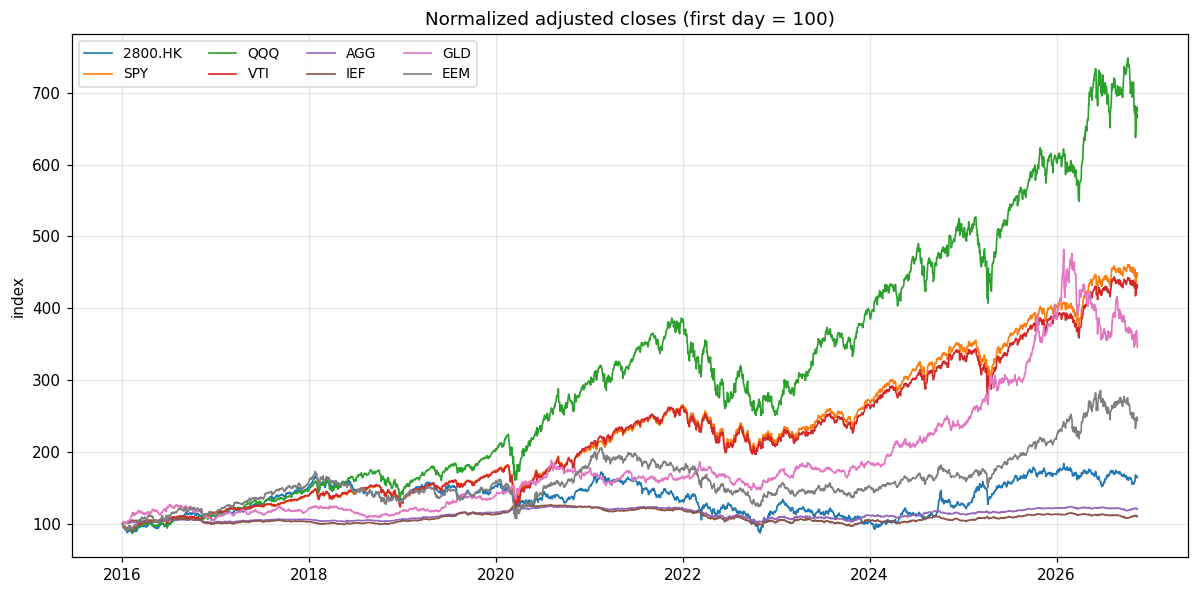

In [3]:
norm = prices / prices.iloc[0] * 100
fig, ax = plt.subplots(figsize=(11, 5.5))
for t in tickers:
    ax.plot(norm.index, norm[t], label=t, linewidth=1.1)
ax.set_title('Normalized adjusted closes (first day = 100)')
ax.set_ylabel('index')
ax.legend(ncol=4, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / 'eda_prices_normalized.png', bbox_inches='tight')
plt.show()

## 3. Return distribution properties

In [4]:
rets = ds.log_returns(prices)
ann = pd.DataFrame({
    'ann_return': rets.mean() * 252,
    'ann_vol': rets.std() * np.sqrt(252),
    'skew': rets.skew(),
    'kurtosis': rets.kurtosis(),
})
ann['sharpe'] = ann['ann_return'] / ann['ann_vol']
cum = (1 + rets).cumprod()
ann['max_drawdown'] = (cum / cum.cummax() - 1).min()
ann.round(3)

,ann_return,ann_vol,skew,kurtosis,sharpe,max_drawdown
ticker,,,,,,
2800.HK,0.045,0.212,-0.446,7.885,0.211,-0.532
SPY,0.135,0.175,-0.609,15.456,0.769,-0.357
QQQ,0.172,0.221,-0.418,7.744,0.779,-0.385
VTI,0.132,0.179,-0.652,15.593,0.735,-0.371
AGG,0.016,0.052,-1.137,20.118,0.313,-0.187
IEF,0.008,0.065,0.149,3.396,0.128,-0.247
GLD,0.112,0.164,-0.636,7.608,0.680,-0.309
EEM,0.080,0.209,-0.736,8.866,0.385,-0.423


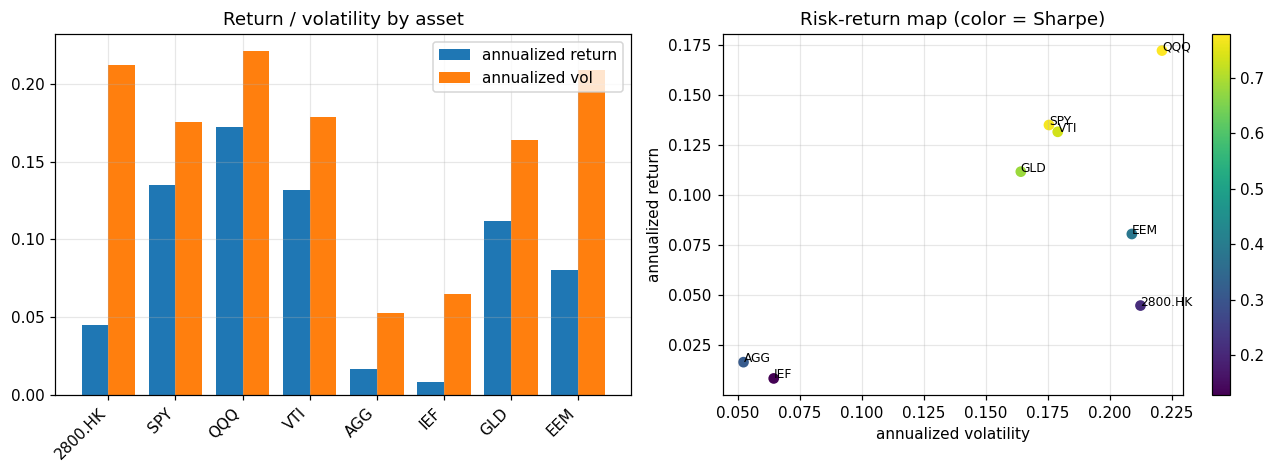

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
x = np.arange(len(tickers))
axes[0].bar(x - 0.2, ann['ann_return'], width=0.4, label='annualized return')
axes[0].bar(x + 0.2, ann['ann_vol'], width=0.4, label='annualized vol')
axes[0].set_xticks(x, tickers, rotation=45, ha='right')
axes[0].set_title('Return / volatility by asset')
axes[0].legend()
sc = axes[1].scatter(ann['ann_vol'], ann['ann_return'], c=ann['sharpe'], cmap='viridis')
for t in tickers:
    axes[1].annotate(t, (ann.loc[t, 'ann_vol'], ann.loc[t, 'ann_return']), fontsize=8)
axes[1].set_xlabel('annualized volatility')
axes[1].set_ylabel('annualized return')
axes[1].set_title('Risk-return map (color = Sharpe)')
fig.colorbar(sc, ax=axes[1])
fig.tight_layout()
fig.savefig(FIG_DIR / 'eda_risk_return.png', bbox_inches='tight')
plt.show()

## 4. Correlation structure

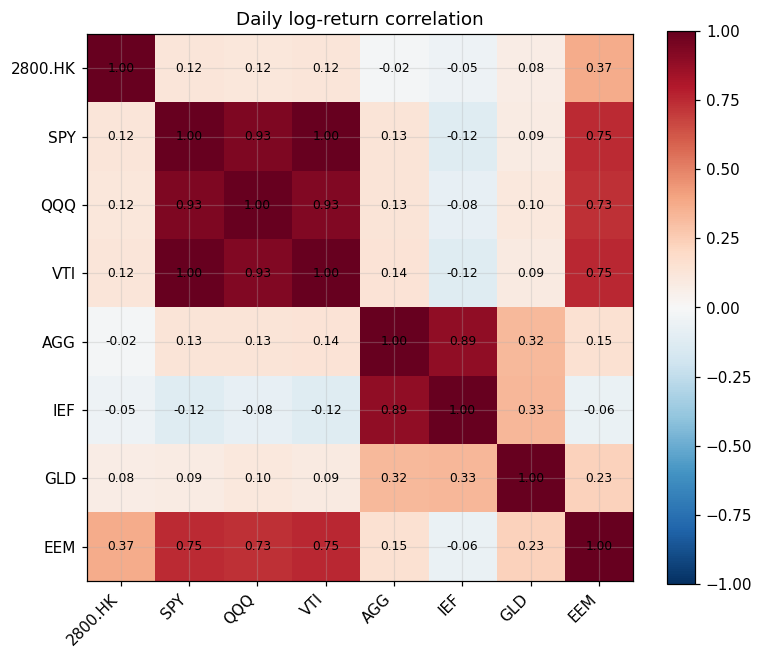

In [6]:
corr = rets.corr()
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(tickers)), tickers, rotation=45, ha='right')
ax.set_yticks(range(len(tickers)), tickers)
for i in range(len(tickers)):
    for j in range(len(tickers)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax)
ax.set_title('Daily log-return correlation')
fig.tight_layout()
fig.savefig(FIG_DIR / 'eda_correlation.png', bbox_inches='tight')
plt.show()

Equity ETFs co-move strongly (diversification benefit is limited within the block),
while bonds (AGG, IEF) and gold provide the low-correlation sleeves the optimizer
uses to push the efficient frontier leftward.

## 5. Rolling volatility and drawdowns

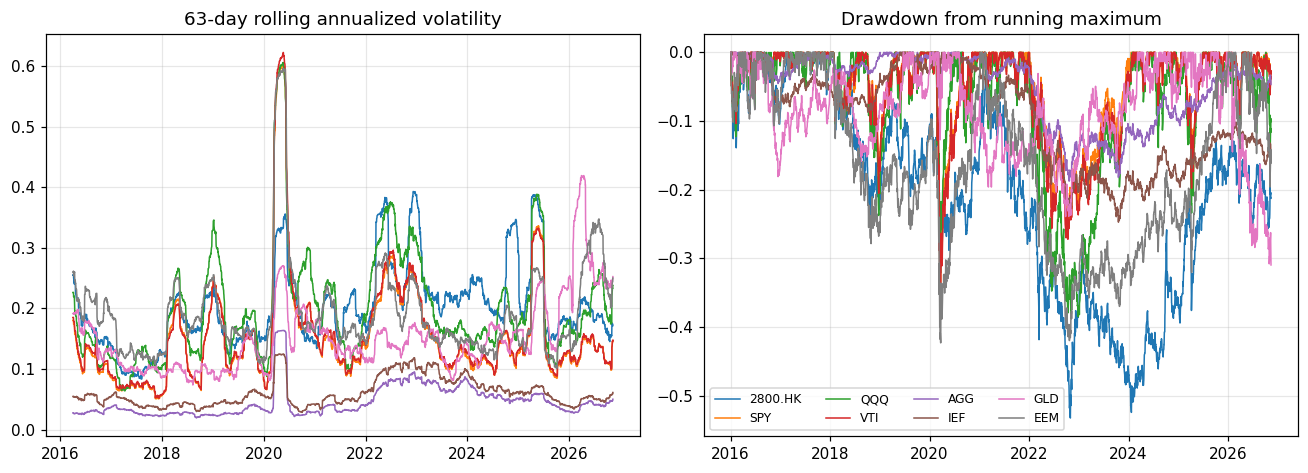

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
roll_vol = rets.rolling(63).std() * np.sqrt(252)
for t in tickers:
    axes[0].plot(roll_vol.index, roll_vol[t], linewidth=1.0, label=t)
axes[0].set_title('63-day rolling annualized volatility')
dd = cum / cum.cummax() - 1
for t in tickers:
    axes[1].plot(dd.index, dd[t], linewidth=1.0, label=t)
axes[1].set_title('Drawdown from running maximum')
axes[1].legend(ncol=4, fontsize=8, loc='lower left')
fig.tight_layout()
fig.savefig(FIG_DIR / 'eda_vol_drawdown.png', bbox_inches='tight')
plt.show()

## 6. Takeaways for modelling

1. **Calendar alignment matters**: US and HK markets have different holidays; the
   panel starts on the first common trading day, which the optimizer and ML feature
   builder both rely on.
2. **Return distributions have fat tails** (positive excess kurtosis across the
   universe): walk-forward validation and a modest ML blend weight (alpha=0.30)
   are used rather than trusting full-sample fits.
3. **Bonds and gold diversify**: the correlation block structure is what makes the
   Markowitz frontier meaningful for conservative profiles.
4. **2022 is a stress case**: equities and bonds fell together, and every trailing
   1-year expected return turned non-negative-negative — the backtest degrades to
   min-volatility in that regime (documented in `BacktestService`).